# Tugas - Klasifikasi dengan Artificial Neural Network (ANN)

| Nama | NRP |
|------|-----|
| Rakha Makarim  | 5054251010 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model ANN (Multi-Layer Perceptron) Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja ANN secara praktik, khususnya:
1. Perbedaan hasil antar fungsi aktivasi (ReLU, Tanh, Logistic/Sigmoid)
2. Pengaruh ukuran arsitektur (`hidden_layer_sizes`) dan jumlah iterasi terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model ANN dengan arsitektur dasar.
   - Lakukan eksperimen fungsi aktivasi dan regularisasi arsitektur.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, roc_auc_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

df = pd.read_csv('../Dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [4]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

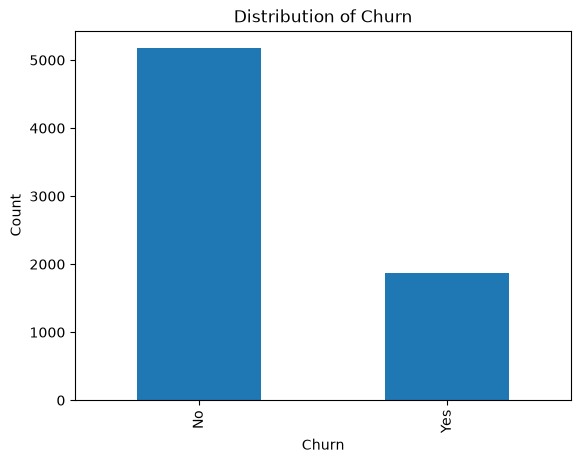

In [5]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
df['Churn'].value_counts().plot(kind='bar')
plt.xlabel('Churn')
plt.ylabel('Count')
plt.title('Distribution of Churn')
plt.show()

Churn
No     [[Axes(0.125,0.545217;0.336957x0.334783), Axes...
Yes    [[Axes(0.125,0.545217;0.336957x0.334783), Axes...
dtype: object

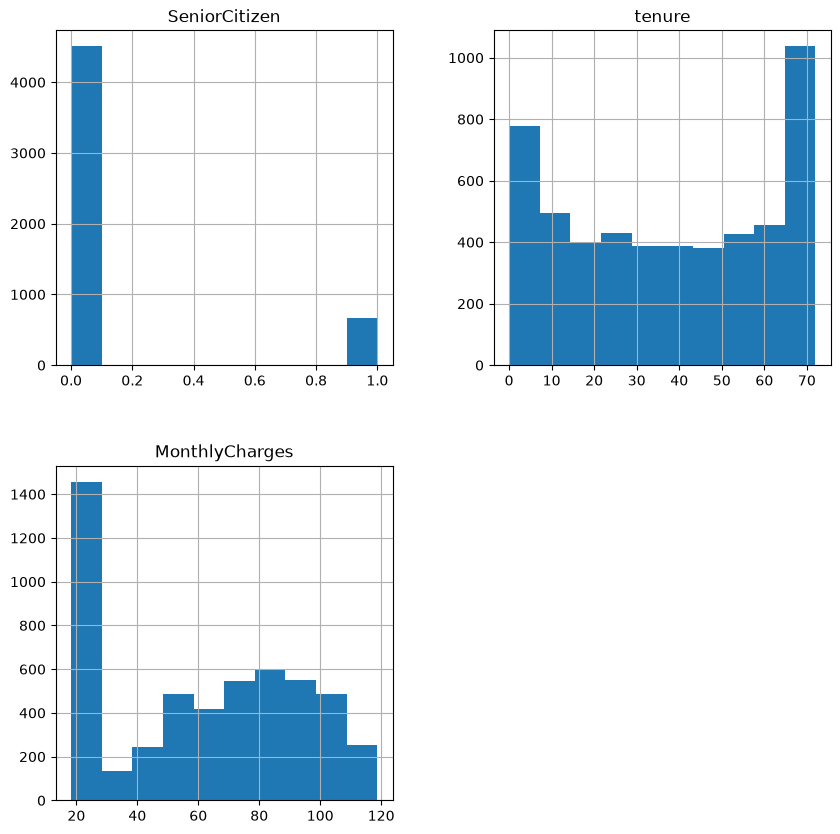

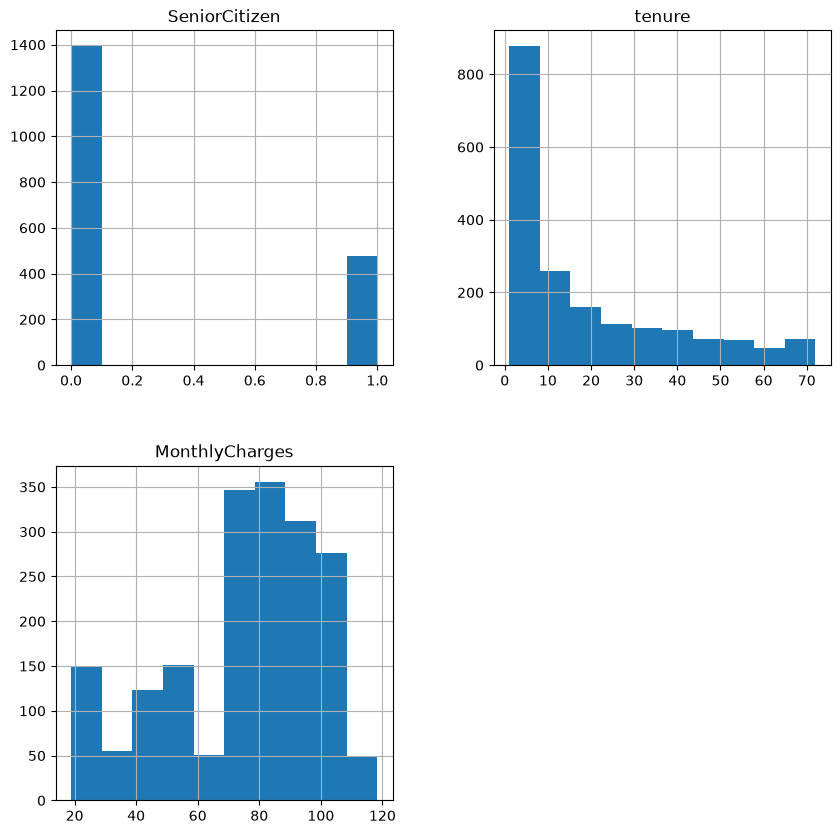

In [6]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau correlation heatmap), dibedakan berdasarkan kelas target.
df.groupby('Churn').hist(figsize=(10, 10))


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

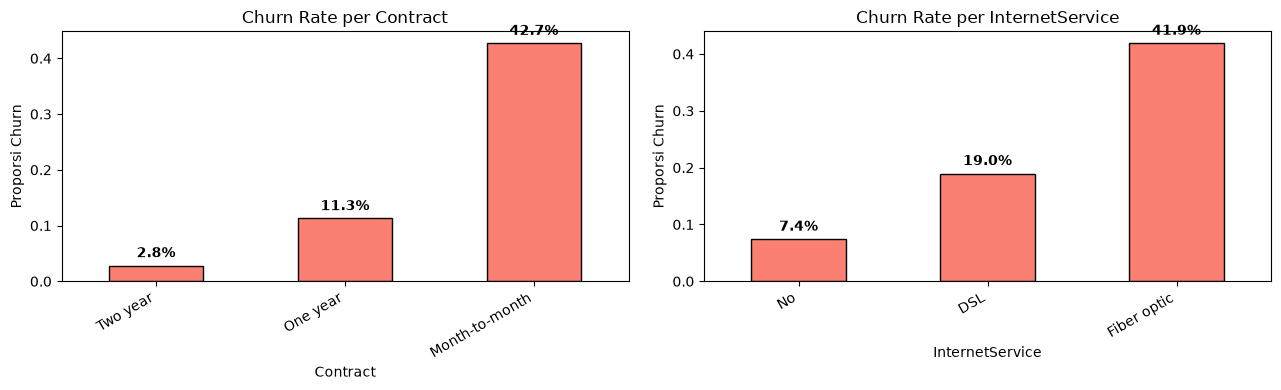

In [7]:
# Churn rate per Contract dan per InternetService
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ['Contract', 'InternetService']):
    rate = df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean()).sort_values()
    bars = rate.plot(kind='bar', ax=ax, color='salmon', edgecolor='black')
    ax.set_title(f'Churn Rate per {col}')
    ax.set_ylabel('Proporsi Churn')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
    for i, v in enumerate(rate):
        ax.text(i, v + 0.015, f'{v:.1%}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


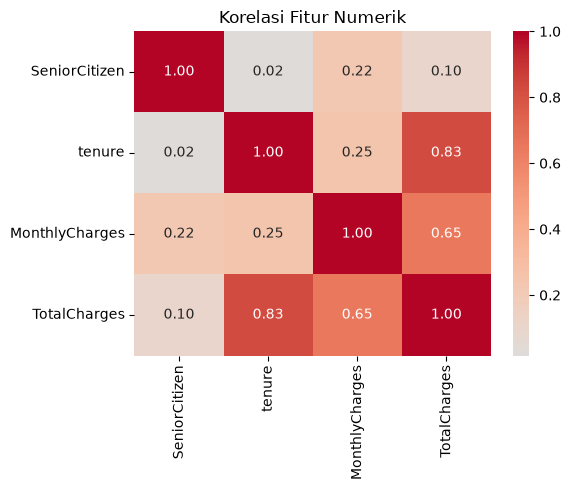

/tmp/ipykernel_14180/2223064257.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='tenure', palette={'No': 'steelblue', 'Yes': 'salmon'}, ax=axes[0])
/tmp/ipykernel_14180/2223064257.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette={'No': 'steelblue', 'Yes': 'salmon'}, ax=axes[1])


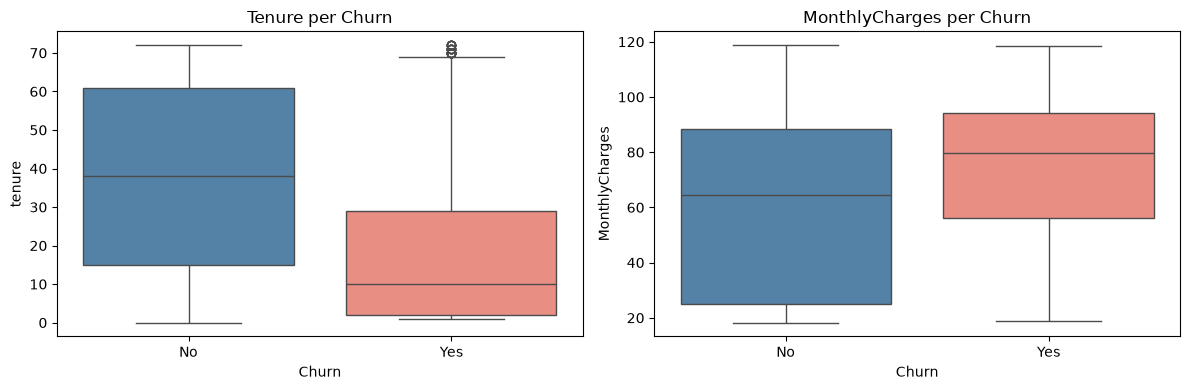

In [8]:
# Korelasi fitur numerik dan sebaran tenure/MonthlyCharges per churn
num_eda = df[['SeniorCitizen', 'tenure', 'MonthlyCharges']].copy()
num_eda['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

plt.figure(figsize=(6, 5))
sns.heatmap(num_eda.corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Korelasi Fitur Numerik')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x='Churn', y='tenure', palette={'No': 'steelblue', 'Yes': 'salmon'}, ax=axes[0])
axes[0].set_title('Tenure per Churn')
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', palette={'No': 'steelblue', 'Yes': 'salmon'}, ax=axes[1])
axes[1].set_title('MonthlyCharges per Churn')
plt.tight_layout()
plt.show()


# 2. Preprocessing

In [9]:
df.drop(columns=['customerID'], inplace=True)

# TotalCharges harus numerik; 11 nilai kosong (" ") menjadi NaN.
# Imputasi median dilakukan di dalam ColumnTransformer -> fit hanya pada train (tanpa data leakage).
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

nums = X_train.select_dtypes(include=[np.number]).columns
cats = X_train.select_dtypes(exclude=[np.number]).columns

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), nums),
    ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), cats)
])
preprocessor.set_output(transform='pandas')

X_train = preprocessor.fit_transform(X_train)  # fit hanya di train
X_test  = preprocessor.transform(X_test)       # test cuma transform
print('Jumlah fitur setelah preprocessing:', X_train.shape[1], '(numerik:',
      len(nums), '| kategorikal 1-hot:', X_train.shape[1] - len(nums), ')')


Jumlah fitur setelah preprocessing: 45 (numerik: 4 | kategorikal 1-hot: 41 )


**Catatan penting:** Sama seperti SVM, ANN juga menghitung penjumlahan berbobot dari fitur-fiturnya, sehingga fitur dengan rentang nilai besar bisa mendominasi proses training dan membuat konvergensi lebih lambat atau tidak stabil. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

# 3. Eksperimen Model

## 3.1 ANN dengan Arsitektur Dasar

Bangun model MLPClassifier sederhana dengan satu hidden layer sebagai baseline.

In [10]:
# Inisialisasi dan latih model MLPClassifier dengan satu hidden layer (misalnya hidden_layer_sizes=(10,))
# dan activation='relu' menggunakan train set (yang sudah discaling).

mlp = MLPClassifier(hidden_layer_sizes=(10,), activation='relu', random_state=42)
mlp.fit(X_train, y_train)
mlp_pred = mlp.predict(X_test)

/home/makarim/miniconda3/envs/collage/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Accuracy : 0.7991483321504613


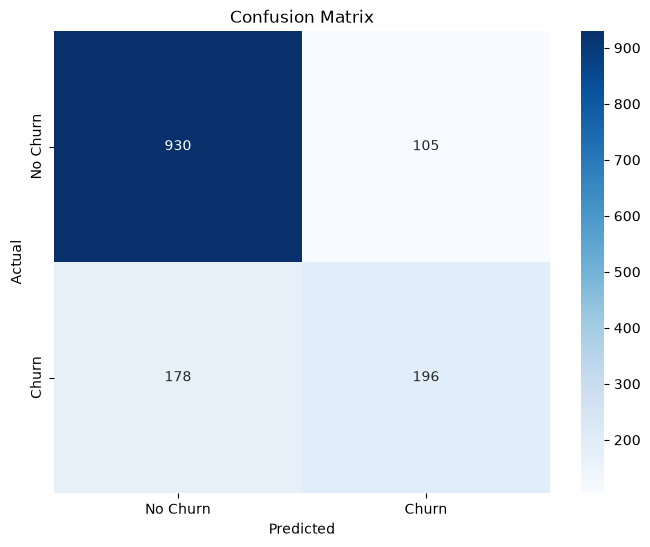

In [11]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, mlp_pred), annot=True, fmt='d', cmap='Blues', xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
print("Accuracy :", accuracy_score(y_test, mlp_pred))

## 3.2 Eksperimen Fungsi Aktivasi

Fungsi aktivasi menentukan bagaimana neuron "mengaktivasikan" keluarannya dan memungkinkan model mempelajari pola non-linear. Bandingkan beberapa pilihan fungsi aktivasi yang tersedia di scikit-learn.

In [12]:
activations = ['relu', 'tanh', 'logistic']
models, rows = {}, []

for act in activations:
    m = MLPClassifier(hidden_layer_sizes=(10,), activation=act,
                      max_iter=1000, random_state=42)
    m.fit(X_train, y_train)
    models[act] = m

    pred_tr = m.predict(X_train)
    pred_te = m.predict(X_test)
    rep_te = classification_report(y_test, pred_te, output_dict=True)

    rows.append({
        'Activation': act,
        'Train Acc': accuracy_score(y_train, pred_tr),
        'Train F1': f1_score(y_train, pred_tr, pos_label='Yes'),
        'Test Acc': accuracy_score(y_test, pred_te),
        'Test Precision': rep_te['Yes']['precision'],
        'Test Recall': rep_te['Yes']['recall'],
        'Test F1': f1_score(y_test, pred_te, pos_label='Yes'),
        'Iter': m.n_iter_,
    })

results_act = pd.DataFrame(rows).set_index('Activation').round(4)
results_act

,Train Acc,Train F1,Test Acc,Test Precision,Test Recall,Test F1,Iter
Activation,,,,,,,
relu,0.8223,0.6375,0.7956,0.6361,0.5374,0.5826,248
tanh,0.8191,0.6263,0.7857,0.6118,0.5267,0.5661,340
logistic,0.8085,0.6037,0.8013,0.6516,0.5401,0.5906,174


## 3.3 Eksperimen Regularisasi: Pengaruh Ukuran Arsitektur terhadap Overfitting

Semakin besar/dalam arsitektur ANN (jumlah neuron dan hidden layer), semakin besar kapasitas model untuk menghafal data training. Pada bagian ini kalian akan mengamati bagaimana perubahan ukuran arsitektur memengaruhi akurasi training dan testing.

In [13]:
best_act = results_act['Test F1'].idxmax()
print(best_act) 

logistic


In [14]:
# Vary jumlah neuron (1..20) dan tambahkan jaringan yang lebih dalam (lebih dari satu hidden layer)
archs = [(i,) for i in range(1, 21)] + [(50,), (100,), (32, 16), (64, 32), (100, 50)]
arch_models = {}

for h in archs:
    m = MLPClassifier(hidden_layer_sizes=h, activation=best_act,
                      max_iter=500, random_state=42)
    m.fit(X_train, y_train)
    arch_models[h] = m

print('Selesai melatih', len(arch_models), 'model arsitektur')


/home/makarim/miniconda3/envs/collage/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/home/makarim/miniconda3/envs/collage/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/home/makarim/miniconda3/envs/collage/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


/home/makarim/miniconda3/envs/collage/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Selesai melatih 25 model arsitektur


/home/makarim/miniconda3/envs/collage/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [15]:
# Plot grafik akurasi training vs testing terhadap ukuran arsitektur dalam satu chart.
# Amati pada arsitektur seberapa besar model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).

arch_results = []
for h, m in arch_models.items():
    pred_tr = m.predict(X_train)
    pred_te = m.predict(X_test)
    arch_results.append({
        'Architecture': str(h),
        'Train F1': f1_score(y_train, pred_tr, average='weighted'),
        'Test F1': f1_score(y_test, pred_te, average='weighted'),
    })
arch_results_df = pd.DataFrame(arch_results).set_index('Architecture').round(4)
arch_results_df.sort_values('Test F1', ascending=False)

,Train F1,Test F1
Architecture,,
"(10,)",0.8021,0.7950
"(1,)",0.7984,0.7943
"(4,)",0.7989,0.7942
"(2,)",0.7971,0.7932
"(8,)",0.8059,0.7923
"(13,)",0.8027,0.7922
"(7,)",0.8060,0.7922
"(9,)",0.8041,0.7910
"(50,)",0.8038,0.7910


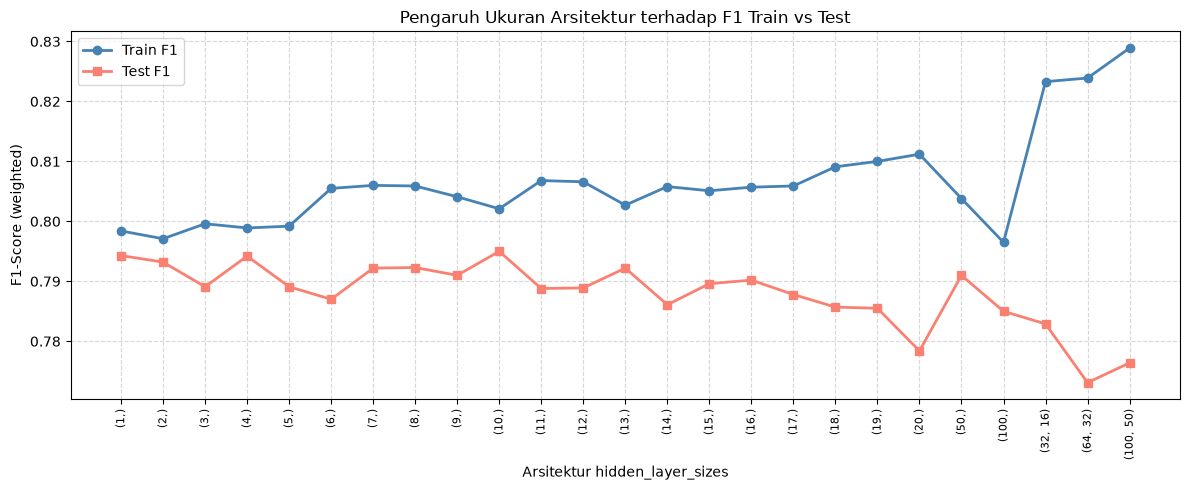

In [16]:
# Plot grafik akurasi training vs testing terhadap ukuran arsitektur dalam satu chart.
plt.figure(figsize=(12, 5))
x = range(len(arch_results_df))
plt.plot(x, arch_results_df['Train F1'], 'o-', label='Train F1', color='steelblue', linewidth=2)
plt.plot(x, arch_results_df['Test F1'], 's-', label='Test F1', color='salmon', linewidth=2)
plt.xticks(x, arch_results_df.index, rotation=90, fontsize=8)
plt.xlabel('Arsitektur hidden_layer_sizes')
plt.ylabel('F1-Score (weighted)')
plt.title('Pengaruh Ukuran Arsitektur terhadap F1 Train vs Test')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# 4. Evaluasi Model

In [17]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model dengan performa terbaik dari tiap eksperimen (3.2 dan 3.3).
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

def evaluate(name, model):
    pred_tr = model.predict(X_train)
    pred_te = model.predict(X_test)
    rep = classification_report(y_test, pred_te, output_dict=True)
    return {
        'Model': name,
        'Train Acc': accuracy_score(y_train, pred_tr),
        'Test Acc': accuracy_score(y_test, pred_te),
        'Precision (Yes)': rep['Yes']['precision'],
        'Recall (Yes)': rep['Yes']['recall'],
        'F1 (Yes)': rep['Yes']['f1-score'],
        'F1 weighted': f1_score(y_test, pred_te, average='weighted'),
    }

best_act = results_act['Test F1'].idxmax()
best_arch_str = arch_results_df['Test F1'].idxmax()
best_arch_tuple = next(k for k in arch_models if str(k) == best_arch_str)

candidates = {
    'Baseline (10, relu)': mlp,
    f'Aktivasi terbaik ({best_act})': models[best_act],
    f'Arsitektur terbaik {best_arch_str}': arch_models[best_arch_tuple],
}

metrics_df = pd.DataFrame([evaluate(n, m) for n, m in candidates.items()]).set_index('Model').round(4)
overall_best_name = metrics_df['F1 (Yes)'].idxmax()
overall_best_model = candidates[overall_best_name]

print('Model dengan performa terbaik overall:', overall_best_name)
display(metrics_df)


Model dengan performa terbaik overall: Aktivasi terbaik (logistic)


,Train Acc,Test Acc,Precision (Yes),Recall (Yes),F1 (Yes),F1 weighted
Model,,,,,,
"Baseline (10, relu)",0.8213,0.7991,0.6512,0.5241,0.5807,0.7917
Aktivasi terbaik (logistic),0.8085,0.8013,0.6516,0.5401,0.5906,0.7950
"Arsitektur terbaik (10,)",0.8085,0.8013,0.6516,0.5401,0.5906,0.7950


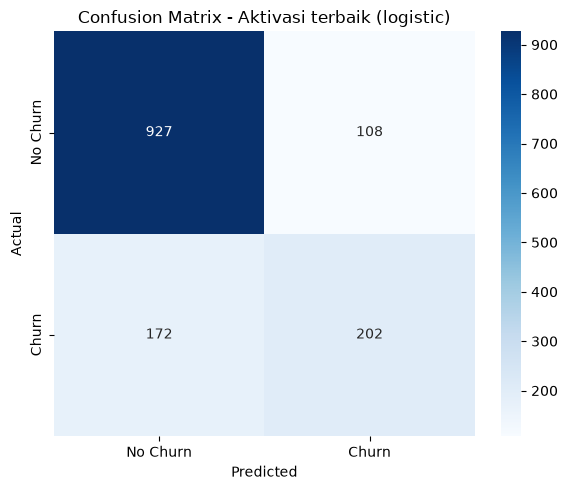

              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.65      0.54      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409

Akurasi: 0.8013 | ROC-AUC: 0.8447


In [18]:
# Tampilkan Confusion Matrix untuk model dengan performa terbaik dalam bentuk heatmap.
y_pred_best = overall_best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best, labels=['No', 'Yes'])

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - {overall_best_name}')
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred_best, target_names=['No Churn', 'Churn']))
print('Akurasi:', round(accuracy_score(y_test, y_pred_best), 4),
      '| ROC-AUC:', round(roc_auc_score((y_test == 'Yes').astype(int),
                                        overall_best_model.predict_proba(X_test)[:, 1]), 4))


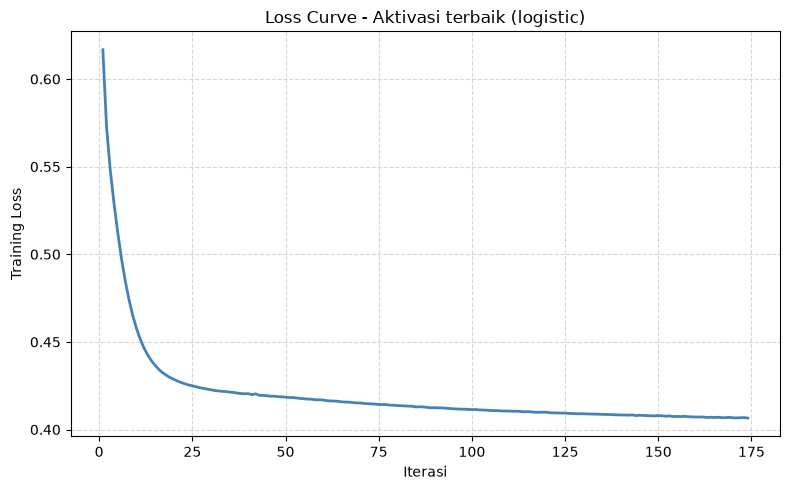

Iterasi terpakai (n_iter_) = 174 dari max_iter = 1000
Loss akhir = 0.4065 | Loss awal = 0.6167
-> Konvergen: pelatihan berhenti sebelum max_iter karena perbaikan loss < tol (1e-4).


In [19]:
# Plot loss curve dari model dengan performa terbaik (atribut model.loss_curve_).
# Amati apakah loss sudah konvergen atau masih menurun saat max_iter tercapai.
loss_curve = overall_best_model.loss_curve_

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(loss_curve) + 1), loss_curve, color='steelblue', linewidth=2)
plt.xlabel('Iterasi')
plt.ylabel('Training Loss')
plt.title(f'Loss Curve - {overall_best_name}')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(f'Iterasi terpakai (n_iter_) = {overall_best_model.n_iter_} dari max_iter = {overall_best_model.max_iter}')
print(f'Loss akhir = {loss_curve[-1]:.4f} | Loss awal = {loss_curve[0]:.4f}')
if overall_best_model.n_iter_ < overall_best_model.max_iter:
    print('-> Konvergen: pelatihan berhenti sebelum max_iter karena perbaikan loss < tol (1e-4).')
else:
    print('-> Mencapai max_iter: perlu dilihat apakah loss masih menurun tajam; jika ya, naikkan max_iter.')


# 5. Analisis

### Hasil Analisis Eksperimen

**0. Catatan preprocessing (perbaikan yang dilakukan)**

`TotalCharges` terbaca sebagai string karena 11 nilai kosong (`" "`), sehingga awalnya kolom tersebut ikut di-one-hot menjadi 6.531 kolom (input ANN ~6.574 dimensi) dan tidak ikut di-scale. Setelah dikonversi ke numerik dan diimputasi median **hanya dari train set** (via `SimpleImputer` di dalam `ColumnTransformer`), jumlah fitur turun menjadi **45 fitur** (4 numerik + 41 one-hot), akurasi baseline naik dari 0.7601 menjadi **0.7991**, dan akurasi train turun dari ~0.99 menjadi 0.82 — bukti bahwa sebelumnya model justru "menghafal" pelanggan lewat fitur ID-like tersebut.

**1. Perbandingan fungsi aktivasi: ReLU vs Tanh vs Logistic**

| Aktivasi | Train Acc | Test Acc | Precision | Recall | F1 (Yes) | Iterasi |
|----------|-----------|----------|-----------|--------|----------|---------|
| ReLU | 0.8223 | 0.7956 | 0.6361 | 0.5374 | 0.5826 | 248 |
| Tanh | 0.8191 | 0.7857 | 0.6118 | 0.5267 | 0.5661 | 340 |
| Logistic | 0.8085 | **0.8013** | **0.6516** | **0.5401** | **0.5906** | 174 |

Perbedaannya **tidak signifikan**: rentang akurasi test hanya 0.7857–0.8013 (selisih ~1.6 poin) dan rentang F1 0.5661–0.5906 (selisih ~2.5 poin), sedangkan semua model memakai arsitektur yang sama (10 neuron). Penjelasannya: fitur pada dataset ini sudah berskala dan di-encode, hubungan fitur–churn sebagian besar bersifat additive/monoton halus (misalnya makin lama tenure dan makin panjang kontrak → makin kecil churn, terlihat dari churn rate kontrak Month-to-month 42.7% vs Two year 2.8%), sehingga batas keputusan yang dipelajari tidak terlalu non-linear dan ketiga aktivasi mampu memodelkannya dengan setara. **Logistic sedikit terbaik** di sini dan justru paling cepat konvergen (174 iterasi vs ReLU 248 dan Tanh 340), kemungkinan karena keluaran sigmoid cocok dengan pola peluang churn yang halus, sementara Tanh paling lambat dan paling buruk pada konfigurasi kecil ini. Perlu diingat selisih ini juga bisa saja menjadi noise akibat satu kali pembagian train/test, sehingga belum boleh dinyatakan "signifikan" tanpa cross-validation.

**2. Pengaruh ukuran arsitektur terhadap overfitting**

Dari 25 arsitektur yang diuji (1–20 neuron, 50, 100 neuron, hingga jaringan berlapis `(32,16)`, `(64,32)`, `(100,50)`) dengan aktivasi terbaik (logistic):

| Arsitektur | Train F1 | Test F1 | Gap |
|------------|----------|---------|-----|
| (10,) — terbaik | 0.8021 | 0.7950 | 0.007 |
| (1,) – (8,) | 0.797–0.806 | 0.787–0.794 | ≤0.01 |
| (20,) | 0.8112 | 0.7784 | 0.033 |
| (32, 16) | 0.8233 | 0.7829 | 0.040 |
| (64, 32) | 0.8239 | 0.7731 | 0.051 |
| (100, 50) | 0.8289 | 0.7764 | 0.053 |

Model mulai menunjukkan **gejala overfitting sejak arsitektur melebihi ~10–13 neuron dan jelas pada jaringan berlapis**. Ciri-cirinya terlihat persis seperti teori: pada grafik, **kurva Train F1 terus naik** (memuncak di `(100,50)` = 0.8289) sementara **kurva Test F1 justru menurun** setelah `(10,)` (dari 0.7950 ke 0.7731 pada `(64,32)`), sehingga gap train-test melebar dari ~0.7 poin menjadi ~5.3 poin. Arsitektur kecil (1–8 neuron) justru menunjukkan train ≈ test, yaitu kapasitas pas-pasan (cenderung underfitting ringan, mis. `(1,)` train 0.7984). Arsitektur **(10,) dengan test F1 0.7950 adalah titik optimal** — kapasitas cukup untuk menangkap pola tanpa menghafal.

**3. Loss curve model terbaik**

Loss model terbaik (`logistic`, `(10,)`) turun dari **0.6167 → 0.4065** dalam **174 iterasi dari max_iter = 1000**, lalu berhenti karena perbaikan loss < `tol` (1e-4). Artinya model **sudah konvergen** dan penambahan iterasi tidak akan banyak menolong; loss yang tersisa (0.4065) bukan berarti model buruk, melainkan mencerminkan batas yang bisa dicapai kapasitas jaringan + noise data. Jika loss curve **masih menurun tajam saat max_iter tercapai**, yang harus dilakukan antara lain: (a) menaikkan `max_iter`, (b) mengaktifkan `early_stopping=True` agar berhenti berdasarkan validasi, (c) mengecilkan regularisasi `alpha` / menaikkan `learning_rate_init` bila konvergensi terlalu lambat, (d) menambah ukuran hidden layer bila loss datar tetapi masih tinggi (tapi hati-hati overfitting), dan (e) memastikan data sudah di-scale agar gradien tidak melemah.

**4. Keterbatasan model: imbalance kelas**

Dataset imbalanced (No 73.5% vs Yes 26.5%) dan itu tercermin di confusion matrix model terbaik: **TN=927, FP=108, FN=172, TP=202** — recall kelas churn hanya **0.54**, artinya **172 dari 374 pelanggan yang benar-benar churn terlewat**. Akurasi 0.8013 dan ROC-AUC 0.8447 terlihat baik, tetapi untuk tujuan bisnis (menahan pelanggan sebelum pindah) recall churn adalah metrik yang paling kritis.


# 6. Kesimpulan dan Saran

### Kesimpulan

1. **Fungsi aktivasi tidak memberi perbedaan signifikan** pada dataset ini: Logistic sedikit terbaik (akurasi 0.8013, F1 0.5906), disusul ReLU (0.7956, F1 0.5826) dan Tanh (0.7857, F1 0.5661). Ketiganya hanya berbeda ~1–2 poin karena hubungan fitur–churn yang relatif halus dan arsitektur yang sama-sama kecil; Logistic unggul tipis sekaligus paling cepat konvergen (174 iterasi).
2. **Arsitektur berpengaruh nyata terhadap overfitting**: titik optimal ada di `(10,)` (test F1 0.7950, gap train-test hanya 0.007). Model mulai overfitting melebihi ~10–13 neuron dan semakin jelas pada jaringan berlapis — `(100,50)` mencapai train F1 tertinggi (0.8289) tetapi test F1 terendah (0.7764), gap melebar hingga ~5.3 poin. Ciri klasiknya: train terus naik, test berhenti lalu turun.
3. **Model sudah konvergen**: loss curve berhenti pada iterasi ke-174 (dari maksimum 1000) karena perbaikan loss < tol, dengan loss 0.6167 → 0.4065, sehingga menaikkan `max_iter` saja tidak menyelesaikan apa pun.
4. **Model akhir** (MLP 10 neuron, aktivasi logistic): akurasi **0.8013**, ROC-AUC **0.8447**, tetapi **recall churn baru 0.54** (172 dari 374 pelanggan churn terlewat) akibat ketidakseimbangan kelas 73.5 : 26.5. Perbaikan preprocessing `TotalCharges` (numerik + imputasi median dari train) juga terbukti penting: fitur turun dari ~6.574 menjadi 45 dan akurasi baseline naik dari 0.7601 ke 0.7991 tanpa kebocoran data.

### Saran

1. **Hyperparameter tuning menyeluruh** dengan `GridSearchCV` + `StratifiedKFold` pada `hidden_layer_sizes`, `alpha` (regularisasi L2), `learning_rate_init`, `max_iter`, dan `early_stopping` — seluruh eksperimen saat ini masih berbasis satu kali split.
2. **Atasi ketidakseimbangan kelas** agar recall churn naik: berikan `sample_weight` yang lebih besar untuk kelas Yes, gunakan SMOTE/undersampling, atau turunkan ambang keputusan threshold (mis. 0.4) — orientasinya ke metrik recall/F1 kelas churn, bukan akurasi semata.
3. **Coba solver lain** (`'sgd'` dengan learning rate schedule `'adaptive'`, atau `'adam'` dengan berbagai `learning_rate_init`) serta bandingkan dengan **early_stopping=True** untuk mencegah overfitting secara otomatis.
4. **Bandingkan dengan model non-neural** (Logistic Regression, Random Forest, XGBoost) — pada data tabular berskala seperti ini ANN tidak selalu yang terbaik, dan Logistic Regression sering menjadi baseline yang sulit dikalahkan.
5. **Feature engineering** untuk menaikkan performa: interaksi seperti `tenure × Contract` atau `MonthlyCharges × InternetService`, serta feature selection pada 45 fitur hasil encoding.
